# Autoencoder: anomaly detection (experimental)

An autoencoder is trained on **normal traffic only**. It learns to rebuild normal flows with low error. A flow it rebuilds badly (high **reconstruction error**) looks unlike normal traffic and is flagged as suspicious. Because it never sees attacks during training, it can flag attack types the supervised models were not trained on, but it is usually less accurate than the Random Forest and MLP. Present it as an experimental extra.

Uses the files from the preprocessing notebook (`processed/`). Everything is evaluated on the validation set.

## 1. Imports

In [1]:
# %pip install tensorflow matplotlib     # uncomment once if missing

import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import keras
from keras import layers
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve,
)

print("keras", keras.__version__)

keras 3.15.1


## 2. Config

In [2]:
PROCESSED_DIR = "processed"
MODEL_DIR = "models"
SEED = 42

ENCODER_UNITS = (32, 16, 8)    # last value is the bottleneck; the decoder mirrors the encoder
LEARNING_RATE = 1e-3
BATCH_SIZE = 512
EPOCHS = 80
PATIENCE = 8

# How the alert threshold is chosen on the validation set:
#   "percentile": flag the top (100 - PERCENTILE)% of normal flows, so false alarms are about that share
#   "best_f1":    the threshold with the best F1 for normal vs attack
THRESHOLD_MODE = "percentile"
PERCENTILE = 95

keras.utils.set_random_seed(SEED)

## 3. Load the data and keep only normal flows for training

In [3]:
proc = Path(PROCESSED_DIR)
data = np.load(proc / "unsw_nb15_processed.npz")
meta = json.loads((proc / "meta.json").read_text())

X_train, X_val = data["X_train"].astype("float32"), data["X_val"].astype("float32")
yb_train, yb_val = data["y_bin_train"], data["y_bin_val"]
ym_val = data["y_multi_val"]
class_names = meta["class_names"]

X_train_normal = X_train[yb_train == 0]     # the autoencoder only ever sees normal traffic
X_val_normal = X_val[yb_val == 0]
n_features = X_train.shape[1]

print(f"train (normal only): {len(X_train_normal):,} of {len(X_train):,} rows")
print(f"validation: {len(X_val):,} rows ({len(X_val_normal):,} normal, {int(yb_val.sum()):,} attack)")

train (normal only): 44,800 of 140,272 rows
validation: 35,069 rows (11,200 normal, 23,869 attack)


## 4. Build and train the autoencoder

The loss is mean squared error between the input and its reconstruction. Early stopping watches the error on **normal validation flows**, so training stops when the model has learned normal traffic as well as it can.

In [4]:
def build_autoencoder(n_in, units):
    inputs = keras.Input(shape=(n_in,))
    x = inputs
    for u in units:                                   # encoder
        x = layers.Dense(u, activation="relu")(x)
    for u in reversed(units[:-1]):                    # decoder
        x = layers.Dense(u, activation="relu")(x)
    outputs = layers.Dense(n_in, activation="linear")(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss="mse")
    return model

ae = build_autoencoder(n_features, ENCODER_UNITS)
ae.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 39)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 39)             │         1,287 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,919 (15.31 KB)

 Trainable params: 3,919 (15.31 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/80
88/88 - 2s - 25ms/step - loss: 0.2547 - val_loss: 0.1392 - learning_rate: 0.0010
Epoch 2/80
88/88 - 0s - 3ms/step - loss: 0.1021 - val_loss: 0.0741 - learning_rate: 0.0010
Epoch 3/80
88/88 - 0s - 3ms/step - loss: 0.0570 - val_loss: 0.0527 - learning_rate: 0.0010
Epoch 4/80
88/88 - 0s - 3ms/step - loss: 0.0332 - val_loss: 0.0390 - learning_rate: 0.0010
Epoch 5/80
88/88 - 0s - 3ms/step - loss: 0.0251 - val_loss: 0.0313 - learning_rate: 0.0010
Epoch 6/80
88/88 - 0s - 4ms/step - loss: 0.0209 - val_loss: 0.0243 - learning_rate: 0.0010
Epoch 7/80
88/88 - 0s - 3ms/step - loss: 0.0183 - val_loss: 0.0192 - learning_rate: 0.0010
Epoch 8/80
88/88 - 0s - 3ms/step - loss: 0.0162 - val_loss: 0.0158 - learning_rate: 0.0010
Epoch 9/80
88/88 - 0s - 3ms/step - loss: 0.0143 - val_loss: 0.0134 - learning_rate: 0.0010
Epoch 10/80
88/88 - 0s - 3ms/step - loss: 0.0127 - val_loss: 0.0119 - learning_rate: 0.0010
Epoch 11/80
88/88 - 0s - 3ms/step - loss: 0.0117 - val_loss: 0.0108 - learning_rate: 0.0

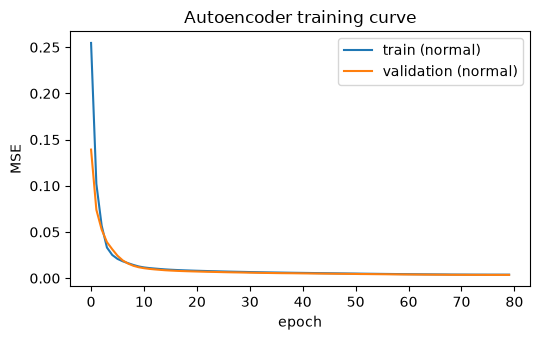

In [5]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
]
t0 = time.time()
hist = ae.fit(X_train_normal, X_train_normal,
              validation_data=(X_val_normal, X_val_normal),
              epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=callbacks, verbose=2)
print(f"trained {len(hist.history['loss'])} epochs in {time.time() - t0:.1f}s")

plt.figure(figsize=(5.5, 3.5))
plt.plot(hist.history["loss"], label="train (normal)")
plt.plot(hist.history["val_loss"], label="validation (normal)")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("Autoencoder training curve"); plt.legend()
plt.tight_layout()
plt.show()

## 5. Anomaly scores

The anomaly score of a flow is its mean squared reconstruction error. If attacks look different from normal traffic, their scores should be higher.

In [6]:
def anomaly_score(model, X):
    recon = model.predict(X, batch_size=4096, verbose=0)
    return np.mean((X - recon) ** 2, axis=1)

score_val = anomaly_score(ae, X_val)

print("median score, normal flows: %.4f" % np.median(score_val[yb_val == 0]))
print("median score, attack flows: %.4f" % np.median(score_val[yb_val == 1]))
print("ROC-AUC (threshold-free):    %.4f" % roc_auc_score(yb_val, score_val))
print("PR-AUC  (threshold-free):    %.4f   (attack share is %.2f)" % (
    average_precision_score(yb_val, score_val), yb_val.mean()))

median score, normal flows: 0.0016
median score, attack flows: 0.0492
ROC-AUC (threshold-free):    0.8365
PR-AUC  (threshold-free):    0.9351   (attack share is 0.68)


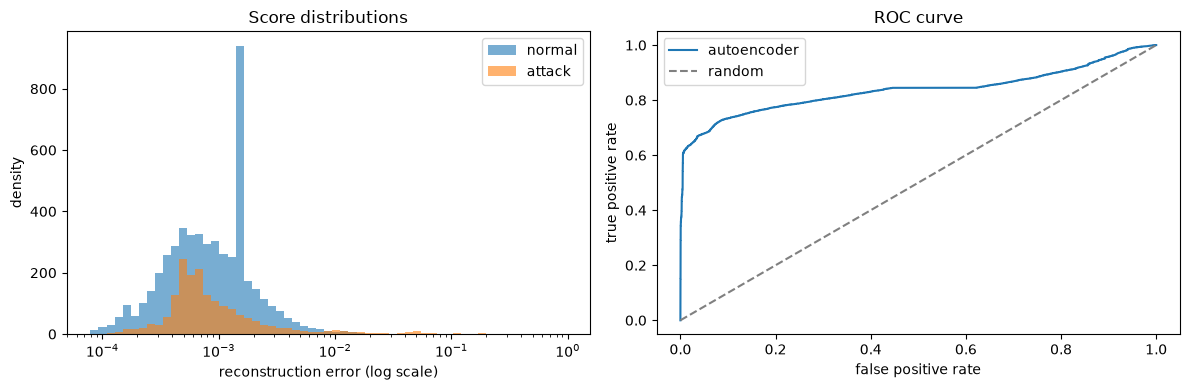

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

bins = np.logspace(np.log10(max(score_val.min(), 1e-6)), np.log10(score_val.max()), 60)
axes[0].hist(score_val[yb_val == 0], bins=bins, alpha=0.6, label="normal", density=True)
axes[0].hist(score_val[yb_val == 1], bins=bins, alpha=0.6, label="attack", density=True)
axes[0].set_xscale("log")
axes[0].set_xlabel("reconstruction error (log scale)"); axes[0].set_ylabel("density")
axes[0].set_title("Score distributions"); axes[0].legend()

fpr_c, tpr_c, _ = roc_curve(yb_val, score_val)
axes[1].plot(fpr_c, tpr_c, label="autoencoder")
axes[1].plot([0, 1], [0, 1], "--", color="grey", label="random")
axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
axes[1].set_title("ROC curve"); axes[1].legend()
plt.tight_layout()
plt.show()

## 6. Choose the alert threshold

The threshold decides how bad a reconstruction has to be before a flow is flagged. The table shows the trade-off. Note that the threshold is chosen on the same validation set used to report results, so the numbers are slightly optimistic. Say so in your report.

In [8]:
normal_scores = score_val[yb_val == 0]

rows = []
for pct in [90, 93, 95, 97, 98, 99]:
    t = np.percentile(normal_scores, pct)
    p = (score_val >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(yb_val, p, labels=[0, 1]).ravel()
    rows.append({"percentile": pct, "threshold": t,
                 "precision": precision_score(yb_val, p, zero_division=0),
                 "recall": recall_score(yb_val, p),
                 "f1": f1_score(yb_val, p),
                 "false_pos_rate": fp_ / (fp_ + tn_)})
pd.DataFrame(rows).round(4)

,percentile,threshold,precision,recall,f1,false_pos_rate
0,90,0.0076,0.9399,0.7340,0.8243,0.10
1,93,0.0105,0.9556,0.7067,0.8125,0.07
2,95,0.0130,0.9666,0.6791,0.7977,0.05
3,97,0.0162,0.9789,0.6522,0.7828,0.03
4,98,0.0202,0.9855,0.6365,0.7734,0.02
5,99,0.0273,0.9925,0.6208,0.7638,0.01


In [9]:
prec, rec, thr = precision_recall_curve(yb_val, score_val)
f1_curve = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
best_f1_threshold = float(thr[np.argmax(f1_curve)])

if THRESHOLD_MODE == "percentile":
    threshold = float(np.percentile(normal_scores, PERCENTILE))
elif THRESHOLD_MODE == "best_f1":
    threshold = best_f1_threshold
else:
    raise ValueError("THRESHOLD_MODE must be 'percentile' or 'best_f1'")

print(f"mode: {THRESHOLD_MODE}   threshold: {threshold:.5f}   (best-F1 threshold would be {best_f1_threshold:.5f})")

mode: percentile   threshold: 0.01299   (best-F1 threshold would be 0.00406)


## 7. Evaluate at the chosen threshold

precision: 0.9666
recall:    0.6791   (7660 attacks missed)
F1:        0.7977
false positive rate: 0.0500   (560 normal flows flagged)


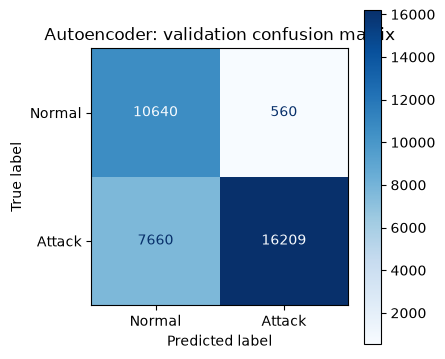

In [10]:
pred = (score_val >= threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(yb_val, pred).ravel()
fpr = fp / (fp + tn)
print(f"precision: {precision_score(yb_val, pred):.4f}")
print(f"recall:    {recall_score(yb_val, pred):.4f}   ({fn} attacks missed)")
print(f"F1:        {f1_score(yb_val, pred):.4f}")
print(f"false positive rate: {fpr:.4f}   ({fp} normal flows flagged)")

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    yb_val, pred, display_labels=["Normal", "Attack"], cmap="Blues", ax=ax, values_format="d")
ax.set_title("Autoencoder: validation confusion matrix")
plt.tight_layout()
plt.show()

### Detection rate by attack type

This is the interesting part for an anomaly detector. It never saw any attack during training, so any attack type it flags counts as detected without labelled examples. For the Normal row, the value is the false alarm rate.

In [11]:
rows = []
for i, name in enumerate(class_names):
    m = ym_val == i
    rows.append({"true class": name, "flows": int(m.sum()),
                 "flagged as anomaly (%)": round(100 * (pred[m] == 1).mean(), 2),
                 "median score": round(float(np.median(score_val[m])), 4)})
pd.DataFrame(rows)

,true class,flows,flagged as anomaly (%),median score
0,Normal,11200,5.00,0.0016
1,DoS,2453,86.02,0.0492
2,Reconnaissance,2099,25.11,0.0015
3,Fuzzers,3637,23.37,0.0017
4,Exploits,6678,61.98,0.0231
5,Generic,8000,99.00,0.1875
6,Other,1002,66.17,0.0471


## 8. Compare with the supervised models

Loads the Random Forest and MLP summaries saved by their notebooks, if they exist.

In [12]:
ae_summary = pd.DataFrame([{
    "model": "Autoencoder binary",
    "precision": precision_score(yb_val, pred),
    "recall": recall_score(yb_val, pred),
    "f1": f1_score(yb_val, pred),
    "false_pos_rate": fpr,
}])

parts = []
for fname in ["rf_validation_summary.csv", "mlp_validation_summary.csv"]:
    p = Path(MODEL_DIR) / fname
    if p.exists():
        parts.append(pd.read_csv(p))
    else:
        print(f"{fname} not found, skipping")
parts.append(ae_summary)
pd.concat(parts, ignore_index=True).round(4)

,model,precision,recall,f1,false_pos_rate
0,RF binary,0.9757,0.9610,0.9683,0.0511
1,RF multiclass (macro),0.6378,0.6286,0.6239,NaN
2,MLP binary,0.9800,0.9279,0.9532,0.0404
3,MLP multiclass (macro),0.7120,0.7350,0.6985,NaN
4,Autoencoder binary,0.9666,0.6791,0.7977,0.0500


## 9. Save the model and threshold

In [13]:
mdir = Path(MODEL_DIR)
mdir.mkdir(exist_ok=True)

ae.save(mdir / "autoencoder.keras")
(mdir / "ae_threshold.json").write_text(json.dumps({
    "threshold": threshold,
    "mode": THRESHOLD_MODE,
    "percentile": PERCENTILE,
    "best_f1_threshold": best_f1_threshold,
    "score": "mean squared reconstruction error",
}, indent=2))
ae_summary.to_csv(mdir / "ae_validation_summary.csv", index=False)

for f in sorted(mdir.glob("ae_*")) + [mdir / "autoencoder.keras"]:
    print(f"{f.name:28s} {f.stat().st_size / 1e3:9.1f} KB")

ae_threshold.json                  0.2 KB
ae_validation_summary.csv          0.1 KB
autoencoder.keras                 90.7 KB


## 10. Using it later (live pipeline)

```python
ae = keras.models.load_model("models/autoencoder.keras")
threshold = json.load(open("models/ae_threshold.json"))["threshold"]

X = transform_with_artifacts(build_model_frame(flows_df))   # from the preprocessing notebook
score = np.mean((X - ae.predict(X, verbose=0)) ** 2, axis=1)
suspicious = score >= threshold
```

On the dashboard, show these as "unusual traffic" alerts, separate from the Random Forest and MLP attack predictions.